## Trick 0: All cells in a jupyter notebook share the same memory
Variables may **overwrite**!

# Question 1

1. import required library first: 
    * `pandas`: for data processing; 
    * `matplotlib`: for data visualization

2. read the csv file using `read_csv` function. Note that the file path could be 
    * just file name: if the data file is in the same dir of your script. 
    * absolute directory path (a lot of /), or relative path (use . or .. ).

In [1]:
#!conda install pandas
#!conda install matplotlib
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/Users/yutongdu/Documents/Teachings_TA/EE2211/Code/Data/Tutorial 2 supp government-expenditure-on-education.csv')   # place your own path to file. Using absolute path here
# For windows users: read_csv(r'D:\EE2211\Code\Data\SOMEDATA.csv')


print(df)
# Or, you can try 
# df.style

    year  total_expenditure_on_education
0   1981                          942517
1   1982                         1358430
2   1983                         1611647
3   1984                         1769728
4   1985                         1812376
5   1986                         1641893
6   1987                         1654115
7   1988                         1604473
8   1989                         1765250
9   1990                         2056374
10  1991                         2816371
11  1992                         2597894
12  1993                         2902886
13  1994                         3318956
14  1995                         3443857
15  1996                         3771955
16  1997                         4449754
17  1998                         4853120
18  1999                         4857488
19  2000                         5867507
20  2001                         6239575
21  2002                         6597955
22  2003                         6214434
23  2004        

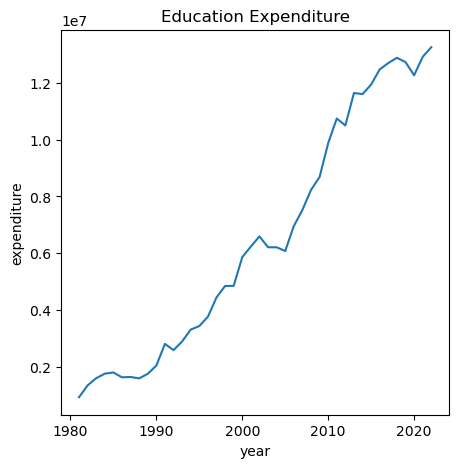

In [2]:
# add new figure (blank canvas)
fig = plt.figure(figsize=(5,5))

# add a subplot (a breakdown region for plot)
ax = fig.add_subplot(1,1,1)
ax.plot(df['year'], df['total_expenditure_on_education'])
ax.set_title('Education Expenditure')
ax.set_xlabel('year')
ax.set_ylabel('expenditure')
plt.show()

## Trick 1: To get a column, use column header

In [4]:
# dump to a list
expenditure = df['total_expenditure_on_education'].to_list()
print(expenditure)
print(type(expenditure))

# dump to a numpy array
years = df['year'].to_numpy()

[942517, 1358430, 1611647, 1769728, 1812376, 1641893, 1654115, 1604473, 1765250, 2056374, 2816371, 2597894, 2902886, 3318956, 3443857, 3771955, 4449754, 4853120, 4857488, 5867507, 6239575, 6597955, 6214434, 6214121, 6082278, 6959285, 7527668, 8229694, 8685056, 9875445, 10740250, 10496911, 11638313, 11598458, 11934956, 12468854, 12690630, 12875992, 12723276, 12259853, 12909908, 13247000]
<class 'list'>


# Question 2
https://beta.data.gov.sg/datasets/317/view

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('./Data/AnnualMotorVehiclePopulationbyVehicleType.csv')      # place your own path to file. Using relative path here

# show first 10 lines
print(df.head(10))

   year                 category          type  number
0  2005  Cars and Station-wagons  Private cars  401638
1  2006  Cars and Station-wagons  Private cars  421904
2  2007  Cars and Station-wagons  Private cars  451745
3  2008  Cars and Station-wagons  Private cars  476634
4  2009  Cars and Station-wagons  Private cars  497116
5  2010  Cars and Station-wagons  Private cars  511125
6  2011  Cars and Station-wagons  Private cars  520614
7  2012  Cars and Station-wagons  Private cars  535233
8  2013  Cars and Station-wagons  Private cars  540063
9  2014  Cars and Station-wagons  Private cars  536882


## Trick 2: Row filtering, use "==" to find boolen series first

In [6]:
print(df['type']=='Omnibuses')

0      False
1      False
2      False
3      False
4      False
       ...  
323    False
324    False
325    False
326    False
327    False
Name: type, Length: 328, dtype: bool


df can directly handle boolen series

In [7]:
df_omnibuses = df[df['type']=='Omnibuses']
df_excursion = df[df['type']=='Excursion buses']
df_private = df[df['type']=='Private buses']
print(df_omnibuses)

     year category       type  number
112  2005    Buses  Omnibuses    3599
113  2006    Buses  Omnibuses    3785
114  2007    Buses  Omnibuses    3761
115  2008    Buses  Omnibuses    3854
116  2009    Buses  Omnibuses    4045
117  2010    Buses  Omnibuses    3981
118  2011    Buses  Omnibuses    4112
119  2012    Buses  Omnibuses    4212
120  2013    Buses  Omnibuses    4552
121  2014    Buses  Omnibuses    4756
214  2015    Buses  Omnibuses    5120
235  2016    Buses  Omnibuses    5470
256  2017    Buses  Omnibuses    5665
277  2018    Buses  Omnibuses    5776
298  2019    Buses  Omnibuses    5863
319  2020    Buses  Omnibuses    5906


**Plot the graph**

Remember that when dealing multiple targets, add legends

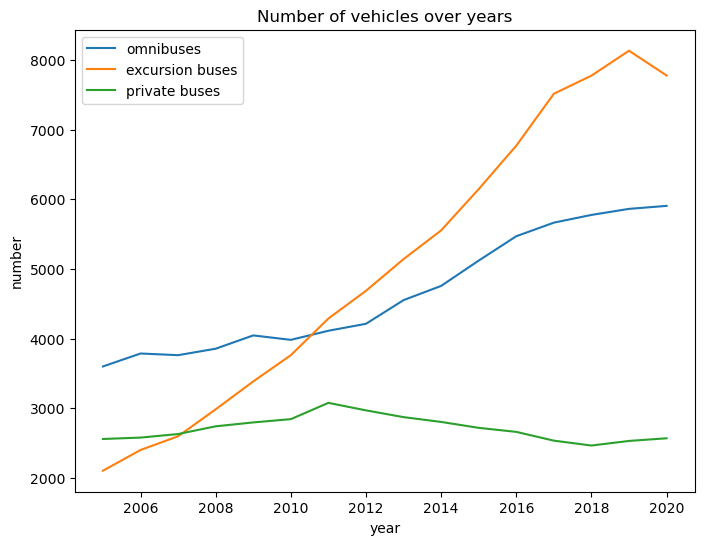

In [8]:
fig, ax = plt.subplots(figsize=(8,6))

ax.plot(df_omnibuses['year'], df_omnibuses['number'], label='omnibuses')
ax.plot(df_excursion['year'], df_excursion['number'], label='excursion buses')
ax.plot(df_private['year'], df_private['number'], label='private buses')
ax.legend()
ax.set_xlabel('year')
ax.set_ylabel('number')
ax.set_title('Number of vehicles over years')
plt.show()

**This standard approach provided by the ans sheet:**
1. use `df.loc[]` to handle the boolen series
2. use `df.index` to get indices of target rows
3. use `df.loc[]` to finally get target rows from indices

In [12]:
# get index numbers of respective classes
idx_excursion = df.loc[df['type']=='Excursion buses'].index
idx_private = df.loc[df['type']=='Private buses'].index
idx_omni = df.loc[df['type']=='Omnibuses'].index
print(idx_omni)

Index([112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 214, 235, 256, 277,
       298, 319],
      dtype='int64')


In [13]:
df_excursion = df.loc[idx_excursion]
df_private = df.loc[idx_private]
df_omnibuses = df.loc[idx_omni]
print(df_omnibuses)

     year category       type  number
112  2005    Buses  Omnibuses    3599
113  2006    Buses  Omnibuses    3785
114  2007    Buses  Omnibuses    3761
115  2008    Buses  Omnibuses    3854
116  2009    Buses  Omnibuses    4045
117  2010    Buses  Omnibuses    3981
118  2011    Buses  Omnibuses    4112
119  2012    Buses  Omnibuses    4212
120  2013    Buses  Omnibuses    4552
121  2014    Buses  Omnibuses    4756
214  2015    Buses  Omnibuses    5120
235  2016    Buses  Omnibuses    5470
256  2017    Buses  Omnibuses    5665
277  2018    Buses  Omnibuses    5776
298  2019    Buses  Omnibuses    5863
319  2020    Buses  Omnibuses    5906


## Trick 3.1 (optional): some typical usage of `df.loc[]` operation
Note: 
1. `df.loc[]` slices through label
2. `:` means all (start to end, inclusive)

**Basic syntax: `df.loc[row_selector, column_selector]`**
1. Select columns(s) by column header: `df.loc[:,"type"]`, `df.loc[:,['year', 'category']]`
2. Select row(s) through indices (df accepts non-numeric index): `df.loc["P001"]`, `df.loc[["P001", "P002"]]`
3. Row filtering through boolen series: `df.loc[df['year']>2005]`
4. Conditional selection: `df.loc[df["year"]>2005, ["type", "number"]]`
5. In-place assign values: `df.loc[df["year"]>2025, "number"]=np.nan`

In [8]:
df.loc[df["year"]>2005, ["type", "number"]]

,type,number
1,Private cars,421904
2,Private cars,451745
3,Private cars,476634
4,Private cars,497116
5,Private cars,511125
...,...,...
323,Excursion buses,7779
324,Cars and Station-wagons,2138
325,Motorcycles and scooters,621
326,Buses,339


## Trick 3.2 (optional): some typical usage of `df.iloc[]` operation
Note: 
1. `df.iloc[]` slices through **position**

**Basic syntax: `df.iloc[row_selector, column_selector]`**
1. Select columns(s) by position: `df.iloc[:,0]`, `df.loc[:,0:5]`
2. Select row(s) by position: `df.iloc[0]`, `df.iloc[[0, 1, 4]]`
3. Select a block: `df.iloc[1:4, 2:5]`
4. Reverse order: row: `df.iloc[::-1]`; column: `df.iloc[:, ::-1]`
5. In-place assign value

Get to know more: click [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.iloc.html)

In [15]:
## non-numeric index
df = pd.DataFrame(
    {
        "year": [2000, 2001, 2002, 2003],
        "type": [110, 105, 98, 108],
    },
    index=["omnibuses", "private buses", "private cars", "trucks"]
)

print(df.iloc[0])           # success
print(df.loc['omnibuses'])  # success
print(df.loc[0])   # failed

year    2000
type     110
Name: omnibuses, dtype: int64
year    2000
type     110
Name: omnibuses, dtype: int64


KeyError: 0

# Question 3. 
Data visualization

In [9]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from pprint import pprint  ## pretty print

iris_dataset = load_iris()
pprint(iris_dataset)

{'DESCR': '.. _iris_dataset:\n'
          '\n'
          'Iris plants dataset\n'
          '--------------------\n'
          '\n'
          '**Data Set Characteristics:**\n'
          '\n'
          ':Number of Instances: 150 (50 in each of three classes)\n'
          ':Number of Attributes: 4 numeric, predictive attributes and the '
          'class\n'
          ':Attribute Information:\n'
          '    - sepal length in cm\n'
          '    - sepal width in cm\n'
          '    - petal length in cm\n'
          '    - petal width in cm\n'
          '    - class:\n'
          '            - Iris-Setosa\n'
          '            - Iris-Versicolour\n'
          '            - Iris-Virginica\n'
          '\n'
          ':Summary Statistics:\n'
          '\n'
          '============== ==== ==== ======= ===== ====================\n'
          '                Min  Max   Mean    SD   Class Correlation\n'
          '============== ==== ==== ======= ===== ====================\n'
          '

**Use train_test_split to separate our dataset, you can setup random_state to ensure the reproducibility**

In [11]:
X_train, X_test, y_train, y_test = train_test_split(iris_dataset['data'],iris_dataset['target'], train_size = 0.7, random_state = 1)
X_train.shape

(105, 4)

In [12]:
df_Xtrain = pd.DataFrame(X_train, columns = iris_dataset['feature_names'])
print(df_Xtrain)

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                  7.7               2.6                6.9               2.3
1                  5.7               3.8                1.7               0.3
2                  5.0               3.6                1.4               0.2
3                  4.8               3.0                1.4               0.3
4                  5.2               2.7                3.9               1.4
..                 ...               ...                ...               ...
100                6.3               2.8                5.1               1.5
101                6.4               3.1                5.5               1.8
102                6.3               2.5                4.9               1.5
103                6.7               3.1                5.6               2.4
104                4.9               3.6                1.4               0.1

[105 rows x 4 columns]


* c = y_train denotes that color will be added based on labels of y_train
* marker = 'o' will change the matplotlib marker type
* hist_kwds will indicate the number of bins in histogram

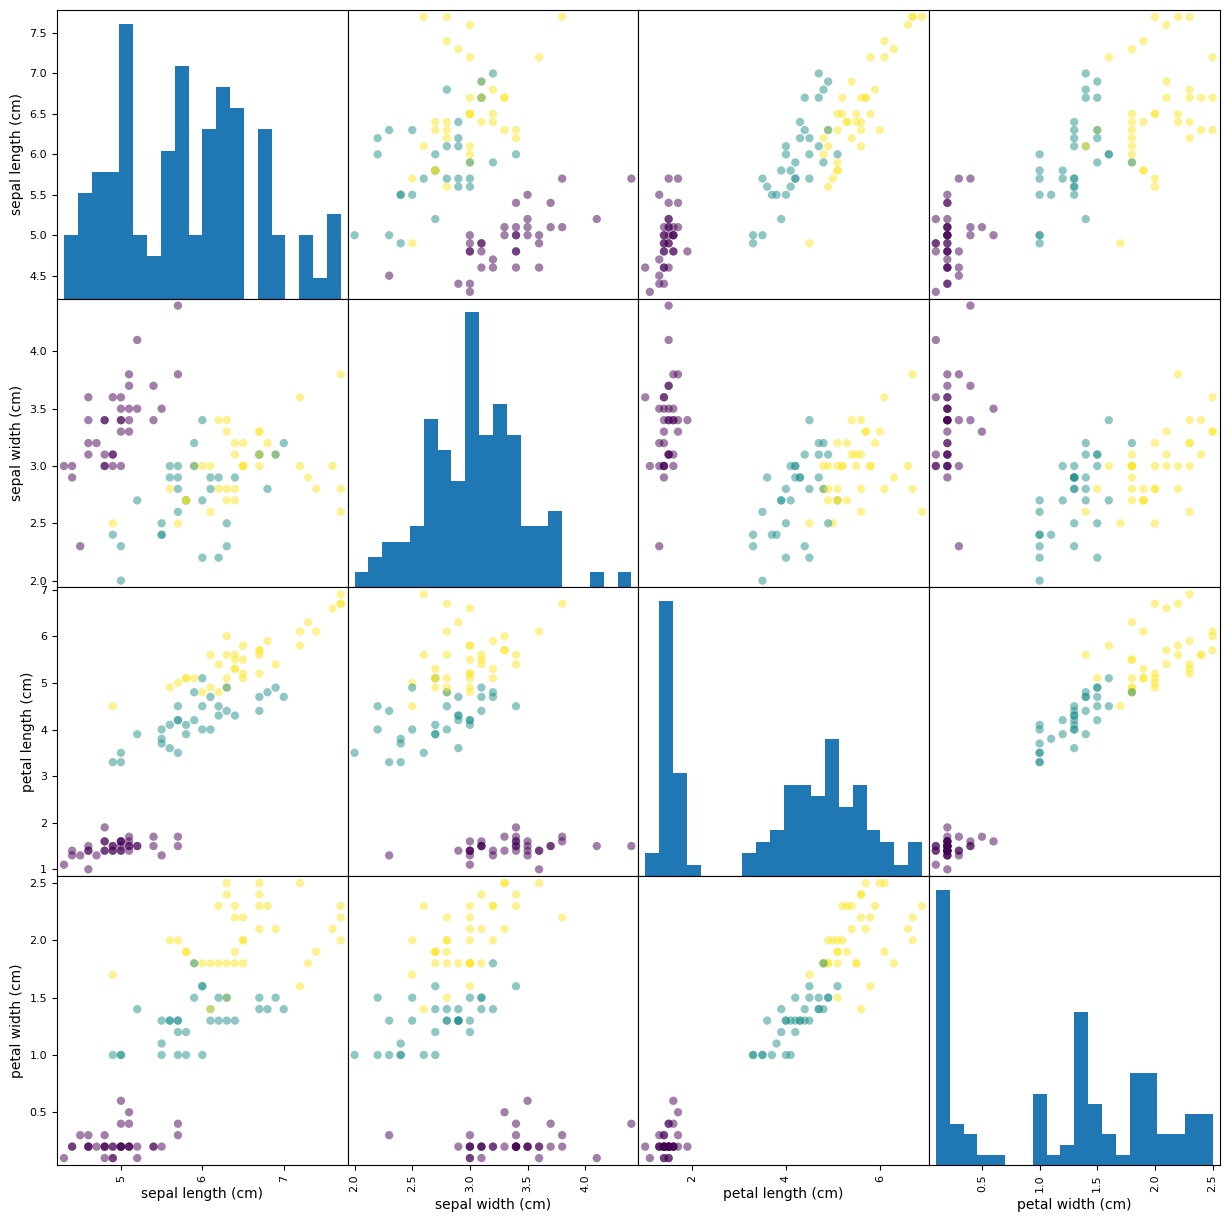

In [13]:
sctmx = pd.plotting.scatter_matrix(df_Xtrain, figsize = (15,15), marker='o', c=y_train, hist_kwds={'bins':20})

# Question 4.

**K-means with/without normalization**

*Example: distance similarity of students with/without normalization*

Intuition: new-A and new-C distance should be similar

before scaling, distance of 
new-A,        new-B,      new-C:
[20.09975124  5.09901951  7.07106781]


after scaling, distance of 
new-A,      new-B,     new-C:
[2.06783949 0.5987184  1.81035429]


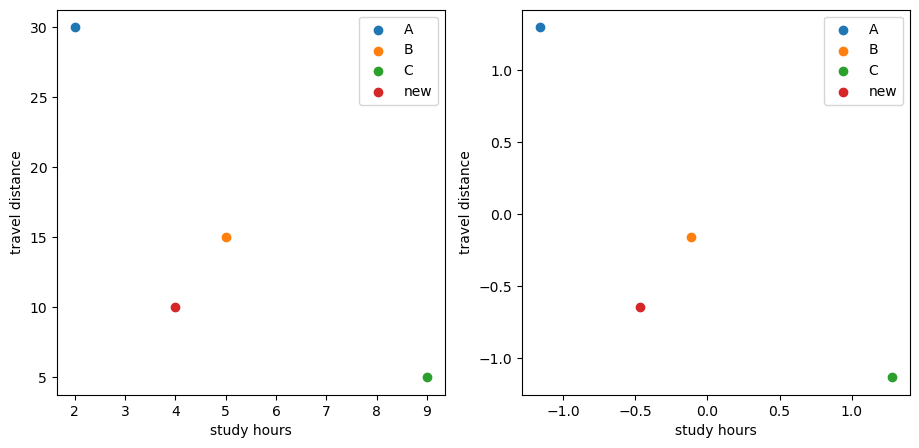

In [14]:
import numpy as np
from sklearn.preprocessing import StandardScaler

df = pd.DataFrame(
    {
        'student': ['A', 'B', 'C'],
        'travel distance': [30, 15, 5],
        'study hours': [2, 5, 9]
    }
)

X_train = df[['study hours', 'travel distance']].to_numpy()

new_student = np.array([[4, 10]])  # 4 hours, 10 km

# Fit the scaler on training data
scaler = StandardScaler()
scaler.fit(X_train)

# Transform training data and the new student
X_train_scaled = scaler.transform(X_train)
new_student_scaled = scaler.transform(new_student)

# Distance calcuation
dist = np.linalg.norm((new_student - X_train), axis=1)
dist_scaled = np.linalg.norm((new_student_scaled - X_train_scaled), axis=1)

print(f'before scaling, distance of \nnew-A,        new-B,      new-C:\n{dist}\n\n')
print(f'after scaling, distance of \nnew-A,      new-B,     new-C:\n{dist_scaled}')

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for i in range(X_train.shape[0]):
    ax[0].scatter(X_train[i,0], X_train[i,1], label=df['student'][i])
ax[0].scatter(new_student[:,0], new_student[:,1], label='new')
ax[0].set_xlabel('study hours')
ax[0].set_ylabel('travel distance')
ax[0].legend()

for i in range(X_train_scaled.shape[0]):
    ax[1].scatter(X_train_scaled[i,0], X_train_scaled[i,1], label=df['student'][i])
ax[1].scatter(new_student_scaled[:,0], new_student_scaled[:,1], label='new')
ax[1].set_xlabel('study hours')
ax[1].set_ylabel('travel distance')
ax[1].legend()

plt.show()

**Visualization of z-score and min-max**

## Trick 4 (optional): use sklearn wisely
**General steps:**
1. Instantiate a class: `std_scaler = StandardScaler()`
2. Fit to your dataset: `std_scaler.fit(data.reshape(-1,1))`
3. Use your fitted model: `zscored = std_scaler.transform(data.reshape(-1,1))`

*Note: `.reshape(-1,1)`: reshape to x-row, 1-column array, "x" means don't care*

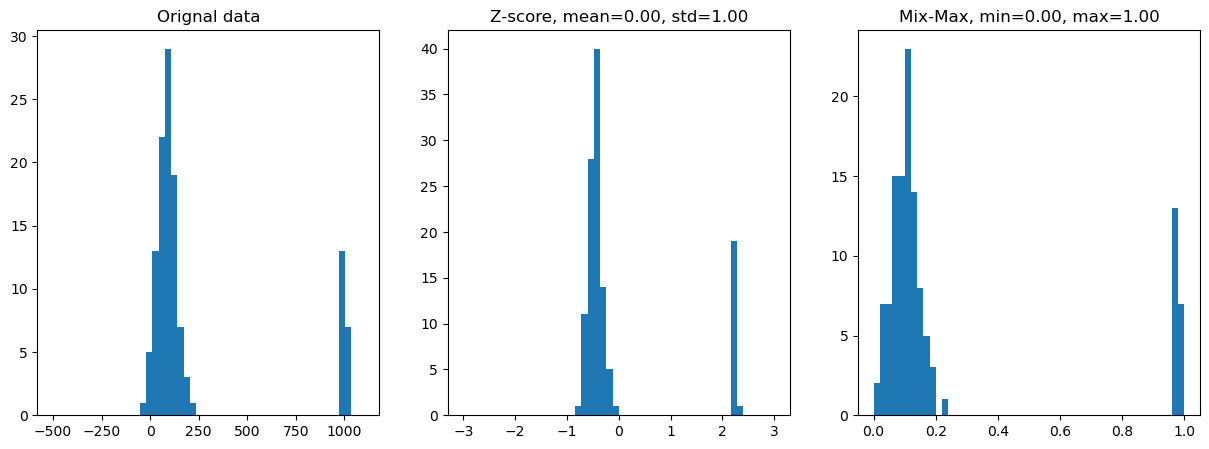

In [21]:
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# generate some random data with outliers
normal_data = np.random.normal(loc=100, scale=50, size=100)
outliers = np.random.normal(loc=1000, scale=10, size=20)
data = np.concatenate((normal_data, outliers), axis=0)

fig, ax = plt.subplots(1,3, figsize=[15,5])
ax[0].hist(data, range=[-500, 1100], bins=50)
ax[0].set_title('Orignal data')

# z-score
std_scaler = StandardScaler()
std_scaler.fit(data.reshape(-1,1))
zscored = std_scaler.transform(data.reshape(-1,1))
## Or, manually: zscored = (data - np.mean(data))/np.std(data)
ax[1].hist(zscored, range=[-3, 3], bins=50)
ax[1].set_title(f'Z-score, mean={np.mean(zscored):.2f}, std={np.std(zscored):.2f}')

# min-max
min_scaler = MinMaxScaler()
min_scaler.fit(data.reshape(-1,1))
minmaxed = min_scaler.transform(data.reshape(-1,1))
## Or, manually: minmaxed = (data - np.min(data))/(np.max(data) - np.min(data))
ax[2].hist(minmaxed, range=[0, 1], bins=50)
ax[2].set_title(f'Mix-Max, min={np.min(minmaxed):.2f}, max={np.max(minmaxed):.2f}')

plt.show()

# Qusetion 5.

*Note: empty-input header will make the very first line as header, while None will give the header name as 0-8*

In [18]:
# import requests
# from io import StringIO
import numpy as np
import pandas as pd

# url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
# response = requests.get(url)
## data = StringIO(response.text)

data = '/Users/yutongdu/Documents/Teachings_TA/EE2211/Code/Data/pima-indians-diabetes.data.csv'
df = pd.read_csv(data, header=None)
# df = pd.read_csv(data)  # first row as header
print(df)

      0    1   2   3    4     5      6   7  8
0     6  148  72  35    0  33.6  0.627  50  1
1     1   85  66  29    0  26.6  0.351  31  0
2     8  183  64   0    0  23.3  0.672  32  1
3     1   89  66  23   94  28.1  0.167  21  0
4     0  137  40  35  168  43.1  2.288  33  1
..   ..  ...  ..  ..  ...   ...    ...  .. ..
763  10  101  76  48  180  32.9  0.171  63  0
764   2  122  70  27    0  36.8  0.340  27  0
765   5  121  72  23  112  26.2  0.245  30  0
766   1  126  60   0    0  30.1  0.349  47  1
767   1   93  70  31    0  30.4  0.315  23  0

[768 rows x 9 columns]


## Trick 5: get to know the (characteristics of) dataset first!

In [19]:
print(df.describe())

                0           1           2           3           4           5  \
count  768.000000  768.000000  768.000000  768.000000  768.000000  768.000000   
mean     3.845052  120.894531   69.105469   20.536458   79.799479   31.992578   
std      3.369578   31.972618   19.355807   15.952218  115.244002    7.884160   
min      0.000000    0.000000    0.000000    0.000000    0.000000    0.000000   
25%      1.000000   99.000000   62.000000    0.000000    0.000000   27.300000   
50%      3.000000  117.000000   72.000000   23.000000   30.500000   32.000000   
75%      6.000000  140.250000   80.000000   32.000000  127.250000   36.600000   
max     17.000000  199.000000  122.000000   99.000000  846.000000   67.100000   

                6           7           8  
count  768.000000  768.000000  768.000000  
mean     0.471876   33.240885    0.348958  
std      0.331329   11.760232    0.476951  
min      0.078000   21.000000    0.000000  
25%      0.243750   24.000000    0.000000  
50%   

In [26]:
(df[[1,2,3,4,5]]==0).sum()

# Alternative: (df.loc[:, [1,2,3,4,5]]==0).sum()

1      5
2     35
3    227
4    374
5     11
dtype: int64

In [29]:
df[[1,2,3,4,5]].replace(0, np.nan)

,1,2,3,4,5
0,148.0,72.0,35.0,NaN,33.6
1,85.0,66.0,29.0,NaN,26.6
2,183.0,64.0,NaN,NaN,23.3
3,89.0,66.0,23.0,94.0,28.1
4,137.0,40.0,35.0,168.0,43.1
...,...,...,...,...,...
763,101.0,76.0,48.0,180.0,32.9
764,122.0,70.0,27.0,NaN,36.8
765,121.0,72.0,23.0,112.0,26.2
766,126.0,60.0,NaN,NaN,30.1


**`df.mean()` can reject NAN responses**

In [20]:
df[[4]].mean()

4    79.799479
dtype: float64

**NAN is very useful in data cleaning.**
- Remind us empty entries: `np.mean()`
- To ignore np.NAN entries: `np.nanmean()`

In [31]:
import numpy as np

# suppose -1 is a value that out of range
A = np.array([[1.1, -1],
              [3.5, 4.9]])
A[A<0] = np.nan
print(A)

[[1.1 nan]
 [3.5 4.9]]


In [32]:
np.mean(A)

np.float64(nan)

In [34]:
np.nanmean(A)

np.float64(3.1666666666666665)